## 3. The belief is recovered in the deep representation

A single token is uninformative about the state, so the belief is reconstructed only in the deep
reps as context accumulates. We compare the **belief-state trajectory** (per-position forward-
algorithm belief vs the network's hidden), with a **linear probe** and **CCA** — the figure
overlays the two trajectories in belief-ring coordinates (they coincide over the whole context).

In [1]:
import sys
import numpy as np, torch
from pyprojroot import here
sys.path.append(str(here()))
from src.code.geometry import predicted_geometry, spectral_hmm, spectral_beliefs
from src.code.eval import cka, cca
from src.code.train import train_inline
from src.code import plot_utils
import matplotlib.pyplot as plt

## Setup: train a transformer on ring-HMM emissions

`runner=hmm` (see `conf/runner/hmm.yaml`) is a transformer sized to reach Bayes on belief-tracking.
We train once and sample a fixed set of sequences everything below reuses.

In [2]:
model, ds, ev, hist = train_inline(['runner=hmm', 'emission_kappa=8.0', 'eval_kwargs.output_hidden_states=true'])
n = ds.n_states
E_lat = predicted_geometry(ds.latent_conditional)                     # predicted latent ring

B, L = 128, 40                                                        # fixed eval sequences
s = torch.empty(B, L, dtype=torch.long, device=ds.device)
s[:, 0] = torch.multinomial(ds.pi, B, replacement=True, generator=ds.rng)
for t in range(1, L):
    s[:, t] = torch.multinomial(ds.T[s[:, t-1]], 1, generator=ds.rng).squeeze(1)
x = torch.multinomial(ds.Em[s.reshape(-1)], 1, generator=ds.rng).reshape(B, L)
ids = torch.cat([torch.full((B,1), ds.start_token, dtype=torch.long, device=ds.device), x], 1)
with torch.no_grad():
    out = model(ids, output_hidden_states=True)
H = out['hidden_states'][-1][:, 1:].reshape(-1, model.config.hidden_size).cpu().numpy()
bel = ds.forward_algorithm(x); belf = bel.reshape(-1, n).cpu().numpy()  # exact beliefs
st = s.cpu().numpy().reshape(-1)                                       # true latent state per position

Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.


INFO:src.code.models:Number of parameters: 402176


Model dims from dataset: vocab_size=25, max_position_embeddings=41


Step,Training Loss
100,2.483586
200,2.392815
300,2.381501
400,2.375524
500,2.373144
600,2.370725
700,2.372009
800,2.368966
900,2.366520
1000,2.367577


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 1. The belief geometry (closed form)

No training needed: the predicted latent geometry is the ring, and the exact belief (forward
algorithm) lives on that ring at a radius set by the emission SNR.

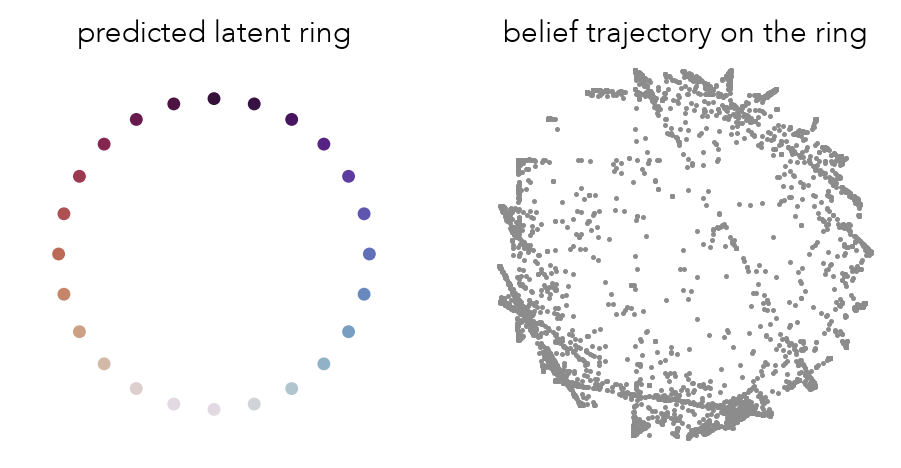

In [3]:
code = belf @ E_lat                                                   # belief-weighted ring position
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
plot_utils.scatter_geometry(ax[0], E_lat[:, :2], 'predicted latent ring')
ax[1].scatter(code[:, 0], code[:, 1], s=4, c='0.55'); ax[1].set_aspect('equal')
ax[1].set_title('belief trajectory on the ring'); plot_utils.FIG.clean(ax[1])
fig.tight_layout();

## 2. Behavior reaches Bayes

In [4]:
p_model = torch.softmax(out['logits'][:, :-1][..., ds.item_tokens], -1).cpu().numpy()
p_bayes = torch.cat([(ds.pi@ds.Em).expand(B,1,-1), (bel[:, :-1]@ds.T)@ds.Em], 1).cpu().numpy()
kl = lambda p,q: float((p*(np.log(p+1e-9)-np.log(q+1e-9))).sum(-1).mean())
print(f'KL(bayes || model) = {kl(p_bayes, p_model):.4f}   (marginal baseline '
      f'{kl(p_bayes, (ds.pi@ds.Em).cpu().numpy()[None,None]):.3f})')

KL(bayes || model) = 0.0043   (marginal baseline 0.523)


## 3. The belief is recovered in the deep representation

A single token is uninformative about the state, so the ring is absent from the token embedding but
reconstructed in the deep reps. Quantify with a **linear probe** and **CCA**; the figure maps each
hidden state linearly to the belief ring (colored by the true state).

belief linearly represented:  probe R2 = 0.955   CCA(hidden, belief trajectory) = 0.939


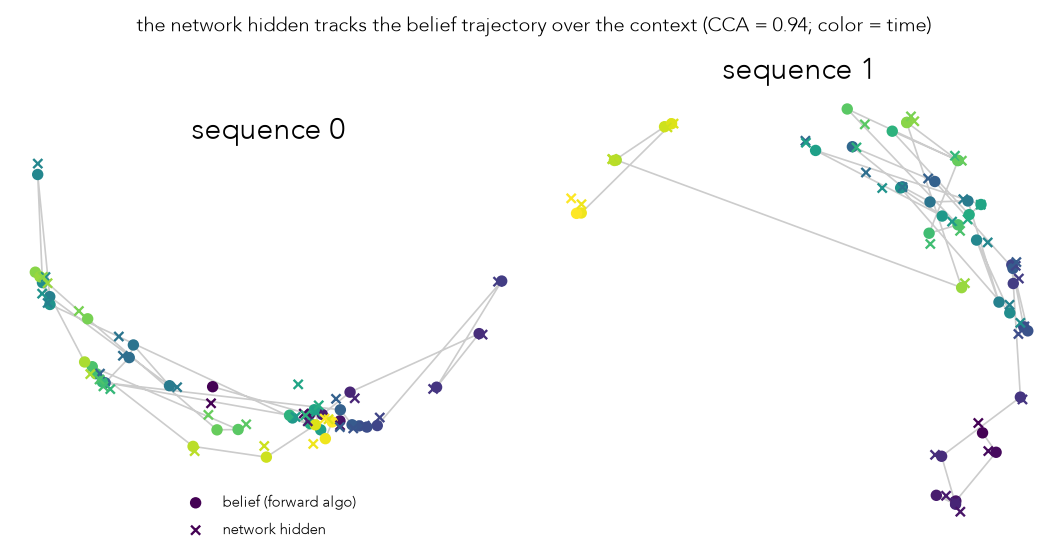

In [5]:
ntr = int(0.8*len(H)); lam = 1e-2                                     # linear probe hidden -> belief
Xtr = np.c_[H[:ntr], np.ones(ntr)]; Xte = np.c_[H[ntr:], np.ones(len(H)-ntr)]
W = np.linalg.solve(Xtr.T@Xtr + lam*np.eye(Xtr.shape[1]), Xtr.T@belf[:ntr]); pred = Xte@W
R2 = 1 - ((belf[ntr:]-pred)**2).sum() / ((belf[ntr:]-belf[ntr:].mean(0))**2).sum()
print(f'belief linearly represented:  probe R2 = {R2:.3f}   CCA(hidden, belief trajectory) = {cca(H, belf):.3f}')

# Compare the belief-state TRAJECTORY: forward-algorithm belief vs the network's hidden, per position.
# Both shown as the 2-D belief-ring coordinate (belief-weighted ring position); network mapped by a
# single linear readout. If the network tracks the belief, the two trajectories coincide.
bcode = (belf @ E_lat[:, :2]).reshape(B, L, 2)                        # forward-algorithm belief traj
Wc = np.linalg.lstsq(np.c_[H, np.ones(len(H))], belf @ E_lat[:, :2], rcond=None)[0]
ncode = (np.c_[H, np.ones(len(H))] @ Wc).reshape(B, L, 2)             # network hidden, mapped
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
for a, seq in zip(ax, [0, 1]):
    a.plot(bcode[seq, :, 0], bcode[seq, :, 1], '-', color='0.8', lw=1, zorder=0)
    a.scatter(bcode[seq, :, 0], bcode[seq, :, 1], c=range(L), cmap='viridis', s=34, zorder=1, label='belief (forward algo)')
    a.scatter(ncode[seq, :, 0], ncode[seq, :, 1], c=range(L), cmap='viridis', marker='x', s=30, lw=1.4, zorder=2, label='network hidden')
    a.set_aspect('equal'); plot_utils.FIG.clean(a); a.set_title(f'sequence {seq}')
ax[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f'the network hidden tracks the belief trajectory over the context '
             f'(CCA = {cca(H, belf):.2f}; color = time)', y=1.02)
fig.tight_layout();

## 4. The network learns the spectral (observable-operator) representation

The spectral HMM (Hsu-Kakade-Zhang) recovers the belief in closed form from *observed* co-occurrence
moments (SVD of the bigram co-occurrence + per-symbol operators); it matches the forward algorithm
exactly up to a linear map. The network's hidden states align with the **spectral basis specifically**
(high CKA), not the raw belief simplex nor a generic (ZCA-whitened) belief — evidence it implements
the spectral computation. (CCA is high for all three, since they're the same belief up to a linear map.)

In [6]:
pi, T, Em = ds.pi.cpu().numpy(), ds.T.cpu().numpy(), ds.Em.cpu().numpy()
U, Bops, b1, b_inf = spectral_hmm(pi, T, Em)
spec = spectral_beliefs(Bops, b1, b_inf, x.cpu().numpy()).reshape(-1, n)
Fc = belf - belf.mean(0); cov = Fc.T@Fc/len(Fc); w, V = np.linalg.eigh(cov)
Fwhite = Fc @ (V @ np.diag(1/np.sqrt(np.clip(w,1e-9,None))) @ V.T)     # ZCA-whitened belief (control)
print('spectral oracle vs forward algorithm:  CCA =', round(cca(spec, belf), 3),
      '(identical up to a linear map)\n')
print(f"{'target':>16s} {'CCA':>7s} {'CKA':>7s}")
for name, Y in [('forward belief', belf), ('spectral belief', spec), ('whitened-fwd', Fwhite)]:
    print(f'{name:>16s} {cca(H, Y):7.3f} {cka(H, Y):7.3f}')
print('\n-> high CKA to the spectral basis but not to forward/whitened: the network is in the'
      ' observable-operator basis, not a generic whitening.')

spectral oracle vs forward algorithm:  CCA = 1.0 (identical up to a linear map)

          target     CCA     CKA


  forward belief   0.939   0.471


 spectral belief   0.973   0.950


    whitened-fwd   0.940   0.416

-> high CKA to the spectral basis but not to forward/whitened: the network is in the observable-operator basis, not a generic whitening.


Since the network aligns with the spectral basis up to a **rotation** (high CKA), we can overlay the
two belief paths directly — no fitted projection, just an orthogonal Procrustes rotation of the
network hidden onto the spectral belief. The path panels put the spectral-algorithm trajectory (●)
beside the rotation-aligned transformer trajectory (×) for a couple of sequences; the parity panel
shows the two coincide coordinate-for-coordinate (rotation only, R² ≈ 0.87). The paths look jagged
because the belief itself does a jumpy walk and the spectral ring is genuinely non-planar (~44% of
its variance is off any 2-D plane) — not because the two disagree.

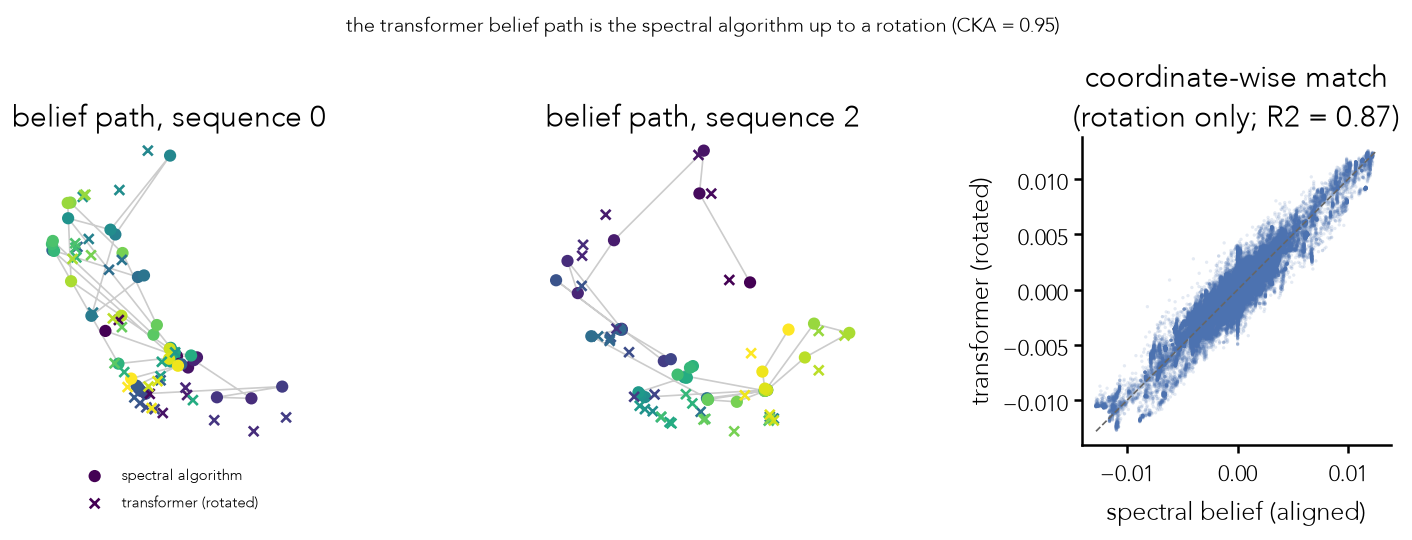

In [7]:
from numpy.linalg import svd as _svd, norm as _norm
from scipy.linalg import orthogonal_procrustes

# rotation-only alignment (justified by the high CKA above): top-n PCA of the hidden, then an
# orthogonal Procrustes rotation onto the spectral belief. Center + unit-norm both first, since a
# rotation cannot fix a scale mismatch (the hidden is far larger than the O(1) belief vector).
Sc = spec - spec.mean(0); Sc /= _norm(Sc)
Hn = (H - H.mean(0)) @ _svd(H - H.mean(0), full_matrices=False)[2][:n].T; Hn /= _norm(Hn)
Rrot, _ = orthogonal_procrustes(Hn, Sc); Hrot = Hn @ Rrot
r2 = 1 - _norm(Hrot - Sc) ** 2 / _norm(Sc) ** 2

# viewing plane = ring plane of the state-averaged spectral belief (the noisy per-token cloud has no
# cleaner 2-D view: the spectral ring is genuinely non-planar).
means = np.stack([Sc[st == k].mean(0) for k in range(n)])
A = _svd(means - means.mean(0), full_matrices=False)[2][:2]
pS = (Sc @ A.T).reshape(B, L, 2); pT = (Hrot @ A.T).reshape(B, L, 2)

fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.3))
for a, seq in zip(ax[:2], [0, 2]):
    a.plot(pS[seq, :, 0], pS[seq, :, 1], '-', color='0.8', lw=1, zorder=0)
    a.scatter(pS[seq, :, 0], pS[seq, :, 1], c=range(L), cmap='viridis', s=40, zorder=1, label='spectral algorithm')
    a.scatter(pT[seq, :, 0], pT[seq, :, 1], c=range(L), cmap='viridis', marker='x', s=34, lw=1.6, zorder=2, label='transformer (rotated)')
    a.set_aspect('equal'); plot_utils.FIG.clean(a); a.set_title(f'belief path, sequence {seq}')
ax[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.02))
ax[2].scatter(Sc.ravel(), Hrot.ravel(), s=4, alpha=0.15, color=plot_utils.FIG.colors['blue'], edgecolors='none')
lim = [min(Sc.min(), Hrot.min()), max(Sc.max(), Hrot.max())]
ax[2].plot(lim, lim, '--', color='0.4', lw=1)
ax[2].set_xlabel('spectral belief (aligned)'); ax[2].set_ylabel('transformer (rotated)')
ax[2].set_title(f'coordinate-wise match\n(rotation only; R2 = {r2:.2f})')
plot_utils.FIG.style_axes(ax[2]); ax[2].set_aspect('equal')
fig.suptitle(f'the transformer belief path is the spectral algorithm up to a rotation (CKA = {cka(H, spec):.2f})', y=1.02)
fig.tight_layout();